# Практична робота №2 — варіант 5
## Оцінювання кіберінцидентів

**Предметна задача:** підготувати дані для визначення пріоритетності реагування на кіберінциденти.

**Рекомендована похідна ознака:** Оціночний ризик = збитки × вузли × коефіцієнт критичності.

> Коефіцієнти критичності для навчального розрахунку: Висока=3, Середня=2, Низька=1.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)


### 1. Завантаження вихідного CSV

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving variant_05_raw.csv to variant_05_raw (4).csv


In [ ]:
file_name = "variant_05_raw.csv"
df = pd.read_csv(file_name, sep=";", encoding="utf-8-sig")
display(df.head())
print("Розмір:", df.shape)
print("Повні дублікати:", df.duplicated().sum())


,ID,Вектор_атаки,Вузли,Простій_год,Критичність_даних,Збитки_тис_грн,Час_реагування_хв,Виявлення_хв,Статус
0,CYB-01,Вразливість ПЗ,110,2.5,Висока,659,176.0,80,Розслідується
1,CYB-02,DDoS,86,11.3,Середня,134,142.0,98,Локалізовано
2,CYB-03,DDoS,117,10.0,high,269,147.0,225,Закрито
3,CYB-04,Фішинг,10,17.7,Висока,262,30.0,154,Закрито
4,CYB-05,Вразливість ПЗ,40,8.3,Висока,407,72.0,145,Розслідується


Розмір: (22, 9)
Повні дублікати: 1


## 2. Структура набору даних та ролі ознак

Ключовим полем набору даних є `ID`, оскільки воно ідентифікує окремий кіберінцидент.

Початковий набір даних містить 22 записи та 9 полів.
Після очищення та видалення повного дубліката `CYB-05` кількість записів становить 21.

Для задачі оцінювання кіберінцидентів числові показники, що характеризують масштаб
і наслідки інциденту, розглядаються як критерії. Категоріальні поля, що описують
умови та контекст інциденту, віднесено до контекстних ознак. Поле `Статус`
визначено як ціль/результат. Створені під час підготовки даних `Коеф_критичності`
та `Оціночний_ризик` є похідними показниками.

In [ ]:
# Словник полів набору даних

dictionary = pd.DataFrame({
    'Поле': [
        'ID',
        'Вектор_атаки',
        'Вузли',
        'Простій_год',
        'Критичність_даних',
        'Збитки_тис_грн',
        'Час_реагування_хв',
        'Виявлення_хв',
        'Статус',
        'Коеф_критичності',
        'Оціночний_ризик'
    ],

    'Тип даних': [
        'Текстовий',
        'Категоріальний',
        'Числовий',
        'Числовий',
        'Категоріальний',
        'Числовий',
        'Числовий',
        'Числовий',
        'Категоріальний',
        'Числовий',
        'Числовий'
    ],

    'Роль у СППР': [
        'Ідентифікатор',
        'Контекстна ознака',
        'Критерій',
        'Критерій',
        'Критерій',
        'Критерій',
        'Критерій',
        'Контекстна ознака',
        'Ціль/результат',
        'Похідний показник',
        'Похідний показник'
    ],

    'Одиниця / категорії': [
        'CYB-XX',
        'DDoS, Фішинг, Вразливість ПЗ, Brute force, Шкідливе ПЗ',
        'кількість вузлів',
        'години',
        'Низька / Середня / Висока',
        'тис. грн',
        'хвилини',
        'хвилини',
        'Розслідується / Локалізовано / Закрито',
        '1 / 2 / 3',
        'умовні одиниці ризику'
    ],

    'Допустимий діапазон': [
        'Унікальний код інциденту',
        'Одна з допустимих категорій атаки',
        'Додатне ціле число',
        'Не менше 0',
        'Низька, Середня або Висока',
        'Не менше 0',
        'Не менше 0',
        'Не менше 0',
        'Одна з трьох допустимих категорій статусу',
        'Від 1 до 3',
        'Не менше 0'
    ]
})

display(dictionary)

,Поле,Тип даних,Роль у СППР,Одиниця / категорії,Допустимий діапазон
0,ID,Текстовий,Ідентифікатор,CYB-XX,Унікальний код інциденту
1,Вектор_атаки,Категоріальний,Контекстна ознака,"DDoS, Фішинг, Вразливість ПЗ, Brute force, Шкі...",Одна з допустимих категорій атаки
2,Вузли,Числовий,Критерій,кількість вузлів,Додатне ціле число
3,Простій_год,Числовий,Критерій,години,Не менше 0
4,Критичність_даних,Категоріальний,Критерій,Низька / Середня / Висока,"Низька, Середня або Висока"
5,Збитки_тис_грн,Числовий,Критерій,тис. грн,Не менше 0
6,Час_реагування_хв,Числовий,Критерій,хвилини,Не менше 0
7,Виявлення_хв,Числовий,Контекстна ознака,хвилини,Не менше 0
8,Статус,Категоріальний,Ціль/результат,Розслідується / Локалізовано / Закрито,Одна з трьох допустимих категорій статусу
9,Коеф_критичності,Числовий,Похідний показник,1 / 2 / 3,Від 1 до 3


In [ ]:
print("Кількість записів до очищення:", len(df))
print("Кількість полів:", len(df.columns))
print("Ключове поле: ID")

Кількість записів до очищення: 22
Кількість полів: 9
Ключове поле: ID


## Паспорт набору даних

| Елемент | Значення |
|---|---|
| Предметна задача СППР | Оцінювання кіберінцидентів та підготовка даних для визначення пріоритетності реагування |
| Джерело/походження даних | Навчальний файл `variant_05_raw.csv` з набору варіантів до практичної роботи |
| Кількість записів до очищення | 22 |
| Кількість полів | 9 |
| Ключове поле / ID | `ID` |
| Період, якого стосуються дані | Не зазначений у вихідному наборі |
| Кількість записів після очищення | 21 |
| Короткий висновок про якість | Виявлено дублікати, пропуск, неузгоджені категорії, помилку числового формату та потенційний викид |

### 2. Початкове профілювання

In [ ]:
profile = pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Пропуски": [df[c].replace("", np.nan).isna().sum() for c in df.columns],
    "Унікальні": df.nunique(dropna=True)
})
display(profile)
print("Критичність:")
print(df["Критичність_даних"].value_counts(dropna=False))


,Тип,Пропуски,Унікальні
ID,object,0,21
Вектор_атаки,object,0,5
Вузли,int64,0,19
Простій_год,object,0,21
Критичність_даних,object,0,6
Збитки_тис_грн,int64,0,20
Час_реагування_хв,float64,1,20
Виявлення_хв,int64,0,21
Статус,object,0,3


Критичність:
Критичність_даних
Висока      9
Середня     7
Низька      3
high        1
середня     1
ВИСОКА      1
Name: count, dtype: int64


### Виявлені проблеми якості даних

За результатами початкового профілювання виявлено:

- 1 пропущене значення у полі `Час_реагування_хв`;
- 1 дубльований запис з ID `CYB-05`;
- неузгоджені категорії у полі `Критичність_даних`: `high`, `середня `, `ВИСОКА`;
- некоректний формат десяткового числа `2,9` у полі `Простій_год`;
- підозріле числове значення `15000` у полі `Збитки_тис_грн`, яке потребує перевірки як потенційний викид.

### 3. Очищення числових полів і категорій

In [ ]:
for c in ["Вузли", "Збитки_тис_грн", "Час_реагування_хв", "Виявлення_хв"]:
    df[c] = pd.to_numeric(df[c].replace("", np.nan), errors="coerce")
df["Простій_год"] = pd.to_numeric(
    df["Простій_год"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

df["Критичність_даних"] = (
    df["Критичність_даних"].astype(str).str.strip().str.lower()
    .map({"висока":"Висока","high":"Висока","середня":"Середня","низька":"Низька"})
)
display(df.head())


,ID,Вектор_атаки,Вузли,Простій_год,Критичність_даних,Збитки_тис_грн,Час_реагування_хв,Виявлення_хв,Статус
0,CYB-01,Вразливість ПЗ,110,2.5,Висока,659,176.0,80,Розслідується
1,CYB-02,DDoS,86,11.3,Середня,134,142.0,98,Локалізовано
2,CYB-03,DDoS,117,10.0,Висока,269,147.0,225,Закрито
3,CYB-04,Фішинг,10,17.7,Висока,262,30.0,154,Закрито
4,CYB-05,Вразливість ПЗ,40,8.3,Висока,407,72.0,145,Розслідується


### 4. Видалення дубліката

In [ ]:
# Видаляємо підтверджений дублікований запис
df = df.drop_duplicates(subset=["ID"], keep="first").reset_index(drop=True)

print("Записів після видалення дубліката:", len(df))
print("Дублікатів за ID:", df.duplicated(subset=["ID"]).sum())

Записів після видалення дубліката: 21
Дублікатів за ID: 0


### 5. Обробка пропуску

In [ ]:
# Після видалення дубліката рахуємо медіану
median_response = df["Час_реагування_хв"].median()

df["Імпутовано_час_реагування"] = (
    df["Час_реагування_хв"].isna().astype(int)
)

df["Час_реагування_хв"] = (
    df["Час_реагування_хв"].fillna(median_response)
)

print("Медіана:", median_response)

display(
    df[df["Імпутовано_час_реагування"] == 1]
)

Медіана: 106.5


,ID,Вектор_атаки,Вузли,Простій_год,Критичність_даних,Збитки_тис_грн,Час_реагування_хв,Виявлення_хв,Статус,Імпутовано_час_реагування
7,CYB-08,Вразливість ПЗ,5,15.8,Висока,136,106.5,64,Закрито,1


### 6. Перевірка викидів за IQR

In [ ]:
q1 = df["Збитки_тис_грн"].quantile(0.25)
q3 = df["Збитки_тис_грн"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
df["Потенційна_аномалія_збитків"] = (df["Збитки_тис_грн"] > upper).astype(int)

print(f"Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}; верхня межа={upper:.2f}")
display(df[df["Потенційна_аномалія_збитків"] == 1][["ID","Збитки_тис_грн"]])


Q1=190.00; Q3=436.00; IQR=246.00; верхня межа=805.00


,ID,Збитки_тис_грн
5,CYB-06,15000


## 7. Створення похідної ознаки

Для оцінювання потенційного рівня ризику кіберінциденту створено похідну ознаку `Оціночний_ризик`.

Коефіцієнтам критичності даних присвоєно такі значення:
- Висока = 3;
- Середня = 2;
- Низька = 1.

Формула:

**Оціночний ризик = Збитки_тис_грн × Вузли × Коеф_критичності**

Чим більше значення похідного показника, тим більший сукупний масштаб потенційного впливу інциденту за використаними критеріями.

In [ ]:
criticality_coef = {"Висока":3, "Середня":2, "Низька":1}
df["Коеф_критичності"] = df["Критичність_даних"].map(criticality_coef)
df["Оціночний_ризик"] = (
    df["Збитки_тис_грн"] * df["Вузли"] * df["Коеф_критичності"]
)
display(df[["ID","Критичність_даних","Збитки_тис_грн","Вузли","Коеф_критичності","Оціночний_ризик"]]
        .sort_values("Оціночний_ризик", ascending=False))


,ID,Критичність_даних,Збитки_тис_грн,Вузли,Коеф_критичності,Оціночний_ризик
5,CYB-06,Середня,15000,44,2,1320000
8,CYB-09,Висока,676,160,3,324480
0,CYB-01,Висока,659,110,3,217470
19,CYB-21,Висока,436,164,3,214512
9,CYB-10,Висока,285,166,3,141930
18,CYB-20,Середня,422,162,2,136728
20,CYB-22,Середня,476,109,2,103768
2,CYB-03,Висока,269,117,3,94419
15,CYB-16,Висока,147,170,3,74970
16,CYB-17,Середня,190,176,2,66880


### 8. Описові статистики

In [ ]:
numeric_cols = ["Вузли","Простій_год","Збитки_тис_грн",
               "Час_реагування_хв","Виявлення_хв","Оціночний_ризик"]
stats = df[numeric_cols].agg(["min","max","mean","median"]).T
stats.columns = ["Min","Max","Середнє","Медіана"]
display(stats.round(2))


,Min,Max,Середнє,Медіана
Вузли,4.0,176.0,92.43,86.0
Простій_год,2.0,17.7,10.04,10.0
Збитки_тис_грн,77.0,15000.0,1030.19,299.0
Час_реагування_хв,8.0,176.0,99.26,106.5
Виявлення_хв,27.0,225.0,130.62,154.0
Оціночний_ризик,2040.0,1320000.0,138772.38,48840.0


### 9. Частоти категорій

In [ ]:
for c in ["Вектор_атаки","Критичність_даних","Статус"]:
    print("\n", c)
    display(df[c].value_counts().rename("Кількість").to_frame())



 Вектор_атаки


,Кількість
Вектор_атаки,
Вразливість ПЗ,8
Фішинг,5
DDoS,4
Brute force,3
Шкідливе ПЗ,1



 Критичність_даних


,Кількість
Критичність_даних,
Висока,10
Середня,8
Низька,3



 Статус


,Кількість
Статус,
Розслідується,10
Закрито,8
Локалізовано,3


### 10. Візуалізації

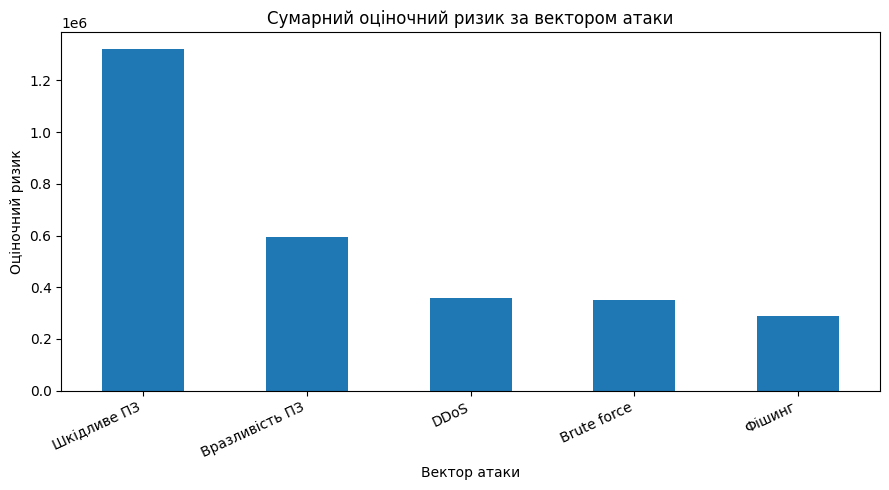

In [ ]:
risk_attack = df.groupby("Вектор_атаки")["Оціночний_ризик"].sum().sort_values(ascending=False)
risk_attack.plot(kind="bar", figsize=(9,5))
plt.title("Сумарний оціночний ризик за вектором атаки")
plt.xlabel("Вектор атаки"); plt.ylabel("Оціночний ризик")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()


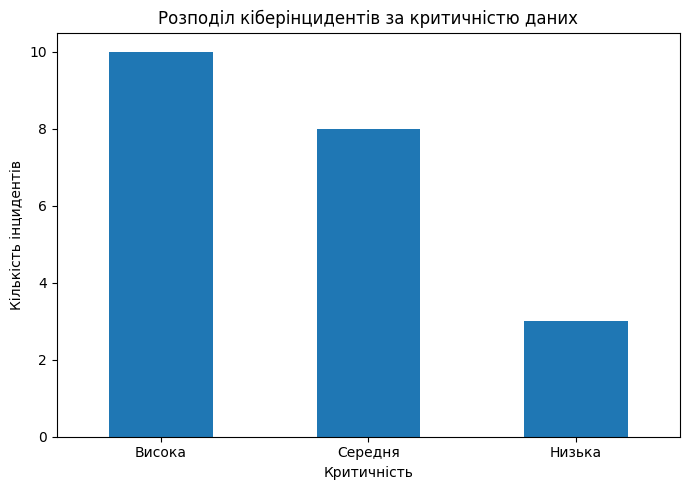

In [ ]:
counts = df["Критичність_даних"].value_counts().reindex(["Висока","Середня","Низька"])
counts.plot(kind="bar", figsize=(7,5))
plt.title("Розподіл кіберінцидентів за критичністю даних")
plt.xlabel("Критичність"); plt.ylabel("Кількість інцидентів")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


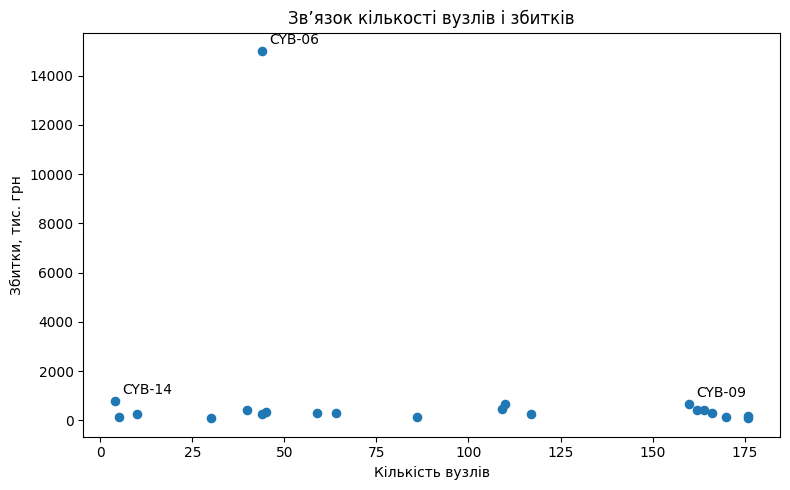

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df["Вузли"], df["Збитки_тис_грн"], s=35)
for _, row in df.nlargest(3, "Збитки_тис_грн").iterrows():
    plt.annotate(row["ID"], (row["Вузли"], row["Збитки_тис_грн"]),
                 xytext=(5,5), textcoords="offset points")
plt.title("Зв’язок кількості вузлів і збитків")
plt.xlabel("Кількість вузлів"); plt.ylabel("Збитки, тис. грн")
plt.tight_layout(); plt.show()


### 11. Журнал очищення

In [ ]:
cleaning_log = pd.DataFrame([
    [1, "Простій_год, CYB-11", 'Формат "2,9"', 'Замінено "," на "."', "Уніфікація числового формату"],
    [2, "Критичність_даних, CYB-03", '"high"', 'Приведено до "Висока"', "Єдиний словник"],
    [3, "Критичність_даних, CYB-13", '"середня " із пробілом', 'Trim + "Середня"', "Єдиний словник"],
    [4, "Критичність_даних, CYB-16", '"ВИСОКА"', 'Приведено до "Висока"', "Єдиний регістр"],
    [5, "CYB-05", "Повний дублікат", "Видалено дубль", "ID — ключ"],
    [6, "Час_реагування_хв, CYB-08", "Пропуск", "Медіана + прапорець імпутації", "Не втрачати запис"],
    [7, "Збитки_тис_грн, CYB-06", "IQR-викид", "Залишено, але позначено", "Потрібна перевірка джерела"]
], columns=["№","Поле/рядок","Проблема","Дія","Обґрунтування"])
display(cleaning_log)


,№,Поле/рядок,Проблема,Дія,Обґрунтування
0,1,"Простій_год, CYB-11","Формат ""2,9""","Замінено "","" на "".""",Уніфікація числового формату
1,2,"Критичність_даних, CYB-03","""high""","Приведено до ""Висока""",Єдиний словник
2,3,"Критичність_даних, CYB-13","""середня "" із пробілом","Trim + ""Середня""",Єдиний словник
3,4,"Критичність_даних, CYB-16","""ВИСОКА""","Приведено до ""Висока""",Єдиний регістр
4,5,CYB-05,Повний дублікат,Видалено дубль,ID — ключ
5,6,"Час_реагування_хв, CYB-08",Пропуск,Медіана + прапорець імпутації,Не втрачати запис
6,7,"Збитки_тис_грн, CYB-06",IQR-викид,"Залишено, але позначено",Потрібна перевірка джерела


## 12. Підсумковий контроль якості

Наведено порівняння стану набору даних до та після очищення.

In [ ]:
quality_control = pd.DataFrame({
    "Показник": [
        "Кількість записів",
        "Кількість полів початкового набору",
        "Кількість повних дублікатів",
        "Кількість пропущених значень",
        "Кількість помилок форматів",
        "Кількість потенційних аномалій",
        "Кількість створених похідних ознак"
    ],
    "До очищення": [
        22,
        9,
        1,
        1,
        1,
        1,
        0
    ],
    "Після очищення": [
        21,
        9,
        0,
        0,
        0,
        1,
        2
    ]
})

display(quality_control)

,Показник,До очищення,Після очищення
0,Кількість записів,22,21
1,Кількість полів початкового набору,9,9
2,Кількість повних дублікатів,1,0
3,Кількість пропущених значень,1,0
4,Кількість помилок форматів,1,0
5,Кількість потенційних аномалій,1,1
6,Кількість створених похідних ознак,0,2


In [ ]:
print("Записів після очищення:", len(df))
print("Дублікатів за ID:", df.duplicated(subset=["ID"]).sum())
print("Пропущених значень:", df.isna().sum().sum())

# Збереження очищеного набору
df.to_csv(
    "variant_05_clean.csv",
    sep=";",
    encoding="utf-8-sig",
    index=False
)

# Збереження журналу очищення
cleaning_log.to_csv(
    "variant_05_cleaning_log.csv",
    sep=";",
    encoding="utf-8-sig",
    index=False
)

print("Очищений набір збережено: variant_05_clean.csv")
print("Журнал очищення збережено: variant_05_cleaning_log.csv")

Записів після очищення: 21
Дублікатів за ID: 0
Пропущених значень: 0
Очищений набір збережено: variant_05_clean.csv
Журнал очищення збережено: variant_05_cleaning_log.csv


## 13. Висновок

У практичній роботі було підготовлено та проаналізовано набір даних про кіберінциденти для подальшого використання в системі підтримки прийняття рішень. Під час початкового профілювання було виявлено пропущене значення, повний дублікований запис, неузгоджені категорії критичності, помилку числового формату та потенційний викид у полі збитків. Дубль `CYB-05` було видалено, категорії критичності уніфіковано, а пропущене значення часу реагування для `CYB-08` замінено медіаною 106,5 хв із фіксацією факту імпутації. Для оцінювання масштабності інцидентів створено похідний показник `Оціночний_ризик`, який розраховується як добуток збитків, кількості вузлів та коефіцієнта критичності. Значення 15000 тис. грн для інциденту `CYB-06` виявлено як потенційний викид за правилом IQR, але автоматично не видалено через необхідність перевірки первинного джерела. Після очищення набір містить 21 унікальний запис без пропущених значень і дублікатів. Підготовлений набір є придатним для подальшого аналітичного використання в СППР за умови додаткової перевірки аномального значення збитків.